# La abertura y la carrera frente a la potencia: la energía de Bond, su oráculo de forma cerrada y el mapa de compromisos

**Pregunta:** ¿Es la potencia del motor igual a la energía de Bond de forma cerrada por el tonelaje, y qué palanca, la abertura o la carrera, da más toneladas para un tamaño de producto requerido?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este notebook usted puede:

- enunciar la tercera teoría de la conminución de Bond, y calcular la energía de una reducción de F80 a P80 con un oráculo que no comparte código con el motor;
- comprobar la potencia del motor contra ese oráculo en una grilla de aberturas y carreras;
- leer la energía específica en kWh por tonelada como el costo de una unidad de reducción de tamaño;
- mapear el tamaño del producto frente a la capacidad para las dos palancas, y encontrar la mejor combinación para un P80 requerido.

## Preparación

Numpy y matplotlib.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Las dos funciones de Bond del oráculo se importan junto al motor; el notebook nunca define las suyas.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from dataclasses import replace

from pipeline.model.crusher import Operating, evaluate
from pipeline.model.crusher.capacity import throughput
from pipeline.oracles import bond_energy_kwh_t, bond_power_kw
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

El caso de referencia S01 otra vez, como base de las barridas. Propietario: este repositorio, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Clase de licencia: MIT; los artefactos versionados los escribe el pipeline a partir de los parámetros de cada caso. Archivo leído: `data/derived/manifests/S01.json`, bloque `params`.

La celda lee el punto de operación.

In [2]:
# Lea el punto de operación de S01
op = Operating(**json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))["params"])
print(op.machine, op.css_mm, op.throw_mm, op.speed_rpm, "| Wi =", op.ore_wi, "kWh/t")

cone-sec 32.0 30.0 360.0 | Wi = 14.0 kWh/t


## Método

**Paso 1, la ley de Bond.** Bond (1952; https://onemine.org/documents/the-third-theory-of-comminution) estableció que la energía para reducir una alimentación de tamaño $F_{80}$ a un producto de tamaño $P_{80}$ es

$$W = 10\,W_i\left(\frac{1}{\sqrt{P_{80}}} - \frac{1}{\sqrt{F_{80}}}\right)\ [\mathrm{kWh/t}], \qquad P_{\mathrm{kW}} = W\,Q$$

con los tamaños en micrómetros y $W_i$ el índice de trabajo de Bond, la energía para reducir el mineral desde tamaño infinito hasta $P_{80} = 100\ \mu\mathrm{m}$. El motor la usa para su potencia. El oráculo `bond_energy_kwh_t` de `data-pipeline/pipeline/oracles.py` implementa la misma ley desde el enunciado del artículo, sin código compartido con el motor, de modo que un desacuerdo sería un hallazgo sobre uno de los dos. La celda corre el motor en S01 y compara su potencia con la del oráculo, alimentado con el F80, el P80 y el tonelaje del propio motor.

In [3]:
# Potencia del motor en S01 frente a la potencia de Bond del oráculo con el F80, el P80 y el tonelaje del propio motor
base = evaluate(op)
energy = bond_energy_kwh_t(base.f80, base.p80, op.ore_wi)
power = bond_power_kw(base.throughput_tph, base.f80, base.p80, op.ore_wi)
print(f"F80 = {base.f80:.3f} mm, P80 = {base.p80:.3f} mm, Wi = {op.ore_wi} kWh/t, Q = {base.throughput_tph:.2f} t/h")
print("energía del oráculo [kWh/t]:", round(energy, 4), "| potencia del oráculo [kW]:", round(power, 4), "| potencia del motor [kW]:", round(base.power_kw, 4))

F80 = 126.033 mm, P80 = 27.698 mm, Wi = 14.0 kWh/t, Q = 643.16 t/h
energía del oráculo [kWh/t]: 0.4469 | potencia del oráculo [kW]: 287.3985 | potencia del motor [kW]: 287.3985


Los dos coinciden en este punto hasta los dígitos impresos. Un punto puede coincidir por casualidad, de modo que la celda siguiente compara el motor y el oráculo en una grilla de 7 aberturas y 5 carreras, 35 puntos de operación, e informa la mayor diferencia relativa. La energía de referencia por apriete del motor, $E_{cs}$, es una cantidad distinta de la energía de Bond $W$: la primera alimenta la función de quiebre, la segunda pone precio a la reducción que resultó.

In [4]:
# Compare la potencia del motor con la del oráculo en una grilla de aberturas y carreras
settings = op.css_mm * np.array([0.5, 0.65, 0.8, 1.0, 1.2, 1.4, 1.6])
throws = np.array([16.0, 23.0, 30.0, 37.0, 44.0])
grid = {(css, th): evaluate(replace(op, css_mm=float(css), throw_mm=float(th))) for css in settings for th in throws}
gap = max(abs(r.power_kw - bond_power_kw(r.throughput_tph, r.f80, r.p80, op.ore_wi)) / r.power_kw for r in grid.values())
print("puntos comparados:", len(grid), "| mayor diferencia relativa motor a oráculo:", f"{gap:.2e}")

puntos comparados: 35 | mayor diferencia relativa motor a oráculo: 0.00e+00


**Paso 2, qué precia la ley.** La energía de Bond depende de los tamaños solo a través de $1/\sqrt{P_{80}} - 1/\sqrt{F_{80}}$, de modo que para una alimentación fija cada vez que el P80 se divide por la mitad cuesta más energía que la vez anterior. La figura dibuja $W$ del oráculo contra P80 para tres tamaños de alimentación y marca el punto de S01. Es una imagen de la ley, no del motor, y dice qué tan empinada se vuelve la cuenta de energía cuando se pide un producto más fino.

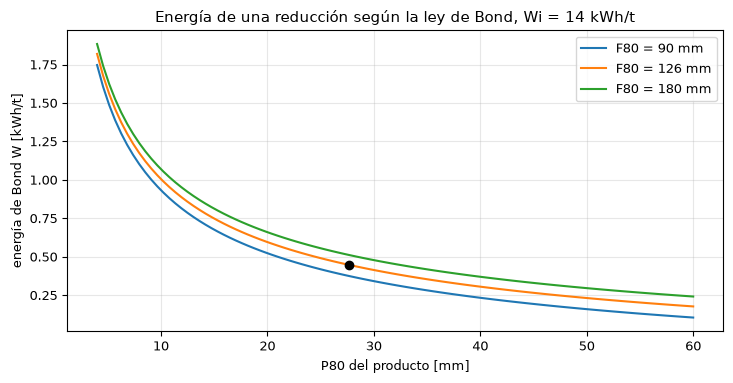

In [5]:
# Grafique la energía de Bond del oráculo contra P80 para tres tamaños de alimentación y marque S01
p80 = np.linspace(4, 60, 100)
fig, ax = plt.subplots()
for f80 in (90.0, base.f80, 180.0):
    ax.plot(p80, [bond_energy_kwh_t(f80, v, op.ore_wi) for v in p80], label=f"F80 = {f80:.0f} mm")
ax.plot([base.p80], [energy], "ko")
ax.set_xlabel("P80 del producto [mm]")
ax.set_ylabel("energía de Bond W [kWh/t]")
ax.set_title("Energía de una reducción según la ley de Bond, Wi = 14 kWh/t")
ax.legend()
fig.tight_layout()
plt.show()

Cada curva cae con fuerza para productos finos y se aplana para los gruesos, y una alimentación más gruesa las sube todas. El punto negro de S01 queda sobre la curva de F80 = 126 en 0,45 kWh/t, un valor modesto porque un chancador secundario reduce solo en un factor de unos 4,5. La figura no muestra si la ley de Bond, calibrada en molienda, es un buen descriptor del chancado grueso; la ficha del modelo de potencia del repositorio registra el hallazgo contrario en los muestreos reales, que toman el tema 05 y el notebook 06.

Antes de dibujar el mapa, la ley de capacidad se puede leer sola: con la abertura y la velocidad de S01 da la capacidad de cada carrera sin correr el motor, y las corridas del motor de la grilla deberían reproducirla, ya que el motor llama a la misma ley. La celda imprime ambas lado a lado para las cinco carreras.

In [6]:
# Capacidad de cada carrera solo con la ley de forma cerrada, junto a la corrida del motor en la grilla
for th in throws:
    law = throughput(op.machine, op.css_mm, float(th), op.speed_rpm)
    print(f"throw {th:4.1f} mm: law {law:6.1f} t/h | engine {grid[(settings[3], th)].throughput_tph:6.1f} t/h | P80 {grid[(settings[3], th)].p80:5.2f} mm")

throw 16.0 mm: law  547.4 t/h | engine  547.4 t/h | P80 25.01 mm
throw 23.0 mm: law  595.3 t/h | engine  595.3 t/h | P80 26.29 mm
throw 30.0 mm: law  643.2 t/h | engine  643.2 t/h | P80 27.70 mm
throw 37.0 mm: law  691.1 t/h | engine  691.1 t/h | P80 29.08 mm
throw 44.0 mm: law  738.9 t/h | engine  738.9 t/h | P80 30.45 mm


**Paso 3, las dos palancas.** La abertura fija la apertura de descarga y el tamaño seleccionado, la carrera abre la abertura media y, a través de K2, deja escapar partículas mayores. Ambas suben la capacidad y engrosan el producto, así que la pregunta es cuál lo hace de manera más barata. La celda traza dos familias de curvas en la grilla de 35 puntos: para cada carrera, la curva de P80 contra capacidad al variar la abertura, y para cada abertura la curva al variar la carrera.

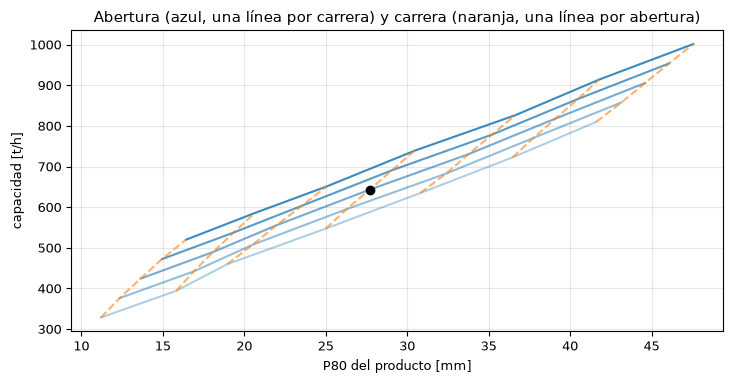

In [7]:
# Mapee capacidad contra P80: una línea por carrera (varía la abertura) y una por abertura (varía la carrera)
fig, ax = plt.subplots()
for th in throws:
    ax.plot([grid[(css, th)].p80 for css in settings], [grid[(css, th)].throughput_tph for css in settings], "-", color="tab:blue", alpha=0.35 + 0.13 * list(throws).index(th))
for css in settings:
    ax.plot([grid[(css, th)].p80 for th in throws], [grid[(css, th)].throughput_tph for th in throws], "--", color="tab:orange", alpha=0.6)
ax.plot([base.p80], [base.throughput_tph], "ko")
ax.set_xlabel("P80 del producto [mm]")
ax.set_ylabel("capacidad [t/h]")
ax.set_title("Abertura (azul, una línea por carrera) y carrera (naranja, una línea por abertura)")
fig.tight_layout()
plt.show()

Las líneas azules, una por carrera, suben con fuerza: a lo largo de ellas la abertura aumenta mucho el P80 por cada tonelada por hora adicional. Las líneas naranjas, una por abertura, son más planas en P80 y más empinadas en toneladas: a lo largo de ellas la carrera sube la capacidad en unos 190 t/h por solo unos 5 mm de P80. La carrera es entonces la palanca más barata para la capacidad, en términos del engrosamiento del producto, y la abertura es la palanca del tamaño mismo. La figura no incluye la potencia, que el último paso incorpora, y es una afirmación del modelo: una máquina real limita la carrera por su diseño mecánico.

**Paso 4, la mejor combinación para un tamaño requerido.** Dado un requisito de P80, la planta quiere las máximas toneladas con la mínima energía. La celda filtra los 35 puntos de operación de la grilla con P80 no mayor que 25 mm, los ordena por capacidad, e imprime el mejor y su energía específica, la energía de Bond del oráculo para su propio F80 y P80, junto al punto de S01.

In [8]:
# Ordene los puntos de la grilla con P80 hasta 25 mm por capacidad e imprima el mejor con su energía específica
feasible = sorted((r for r in grid.values() if r.p80 <= 25.0), key=lambda r: -r.throughput_tph)
print("puntos con P80 <= 25 mm:", len(feasible), "de", len(grid))
for r in feasible[:3]:
    print(f"CSS {r.op.css_mm:5.1f} mm, throw {r.op.throw_mm:4.1f} mm: {r.throughput_tph:6.1f} t/h, P80 {r.p80:5.2f} mm, {bond_energy_kwh_t(r.f80, r.p80, op.ore_wi):.3f} kWh/t")
print(f"S01: CSS {op.css_mm} mm, throw {op.throw_mm} mm: {base.throughput_tph:.1f} t/h, P80 {base.p80:.2f} mm, {bond_energy_kwh_t(base.f80, base.p80, op.ore_wi):.3f} kWh/t")

puntos con P80 <= 25 mm: 14 de 35
CSS  25.6 mm, throw 37.0 mm:  603.5 t/h, P80 23.53 mm, 0.518 kWh/t
CSS  20.8 mm, throw 44.0 mm:  585.7 t/h, P80 20.65 mm, 0.580 kWh/t
CSS  25.6 mm, throw 30.0 mm:  555.6 t/h, P80 21.98 mm, 0.550 kWh/t
S01: CSS 32.0 mm, throw 30.0 mm: 643.2 t/h, P80 27.70 mm, 0.447 kWh/t


## Resultados

**Respuesta:** la potencia del motor es igual a la potencia de Bond de forma cerrada: en S01 ambas son 287,3985 kW para F80 = 126,033 mm, P80 = 27,698 mm y 643,16 t/h (0,4469 kWh/t), y en 35 puntos de operación la mayor diferencia relativa es 0,00e+00: los dos son idénticos hasta el último bit, como se espera de la misma forma cerrada en doble precisión. Respecto de las palancas, la carrera compra capacidad de manera barata en términos de tamaño de producto, 192 t/h por 5,4 mm de P80 a lo largo de la línea de abertura constante de S01, mientras la abertura compra tamaño. Bajo un requisito de P80 de 25 mm califican 14 de los 35 puntos, y el mejor es una abertura más cerrada con más carrera, CSS 25,6 mm y carrera 37 mm: 603,5 t/h con P80 23,53 mm y 0,518 kWh/t, frente a los 643,2 t/h con 27,70 mm y 0,447 kWh/t de S01, de modo que el producto más fino cuesta 6,2 por ciento del tonelaje y 15,9 por ciento más energía por tonelada. Con la misma abertura y la carrera propia de S01 el tonelaje sería 555,6 t/h, 48 t/h menos.

La primera figura muestra la pendiente de la energía de Bond para productos finos, la segunda las dos familias de líneas. Un validador concluiría que la potencia de este motor es una implementación fiel de la ley de Bond y nada más: su coincidencia con el oráculo prueba el código, no la ley. Lo que este notebook no muestra es que la ley de Bond prediga la potencia de un chancador real; la paridad de potencia frente a las mediciones del HP500, en el tema 05 y el notebook 06, es donde eso se prueba, con un resultado negativo que el repositorio informa.

## Resumen

La ley de Bond es el único lugar donde el motor convierte reducción de tamaño en potencia, y una forma cerrada independiente la reproduce hasta el redondeo. Las dos palancas del operador actúan de manera distinta: la carrera abre la máquina y la abertura fija el tamaño, y un P80 requerido elige una combinación entre ellas. El tema siguiente deja los casos sintéticos y corre el motor calibrado en los diez muestreos reales de un cono industrial.

## Referencias

- Bond, F. C. (1952), The third theory of comminution, Transactions AIME 193, 484-494. https://onemine.org/documents/the-third-theory-of-comminution
- Evertsson, C. M. (2000), Cone crusher performance, doctoral thesis, Chalmers University of Technology. https://research.chalmers.se/en/publication/759
- Evertsson, C. M. (1999), Modelling of flow in cone crushers, Minerals Engineering 12(12), 1479-1499. https://doi.org/10.1016/S0892-6875(99)00136-3
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193